<img src="images/cabecera.png" alt="Alternative text" />

# <center> Clase 03: Software para el desarrollo de redes neuronales profundas </center>


**Objetivo:** 
- Conocer las principales librerías de redes neuronales: pytorch, tensorflow, keras, fastai, etc.
- Conocer las principales herramientas auxiliares: sagemaker, colab, tensorboard, mlflow, github, etc.

-----------------------------

**Agenda:**

    3.1.- Librerías de aprendizaje profundo
      3.1.1.- Pytorch
      3.1.2.- Tensorflow / Keras
      3.1.3.- Librerías de alto nivel
      3.1.4.- Otras librerías de aprendizaje profundo
      
    3.2.- Herramientas auxiliares
      3.2.1.- Entornos cloud
      3.2.2.- Herramientas de visualización
      
    3.3.- Herramientas para reutilizar código abierto
      3.3.1.- Instalación de las librerías
      3.3.2.- Servicios de apoyo a la programación
      3.3.3.- Plataformas de competición y aprendizaje

-----------------------------

**Preguntas de examen:**
- ¿Qué diferencias hay entre tensorflow y pytorch?
- ¿De qué sirven librerías como keras, pytorch-lightining o fast.ai?
- Mencionar tres formas de disponer de un entorno de desarrollo de redes neuronales

## 3.1.- Librerías de aprendizaje profundo

Hoy en día existen muy buenas librerías de código abierto para Python de deep learning. Las primeras librerías que se intrudujeron para Python para computar eficientemente los gradientes de las redes neuronales profundas fueron Theano y Lasagne, las cuales se podían utilizar fácilmente al quedar encapsuladas dentro de **Keras**, una librería de alto nivel que simplificaba el desarrollo de estos modelos a través de una capa de abstracción superior mucho más sencilla y asequible.

Los frameworks de programación hoy en día más populares son **TensorFlow** (impulsado por Google/Alphabet) y **PyTorch** (impulsado por Facebook/Meta). Ambos son utilizados hoy en día con frecuencia, aunque en los últimos años se he visto una mayor preferencia entre los investigadores por PyTorch por su mejor encaje con Python (más "pythonic"), lo que no quita que TensorFlow sea el preferido para la industrialización de procesos al disponer de un rico ecosistema de herramientas de despliegue desarrolladas por el equipo de Google alrededor de él.

La primera versión de TensorFlow, lanzada para el público a finales de 2015, mostró ciertas carencias y complejidades, como la de tener que establecer un grafo estático dentro de una estructura de sesiones que para muchos data scientists nos resultaba incómoda y poco intuitiva, pues todo ello debía ejecutarse en diferido (modo "lazy"). Por est motivo, lo que más se utilizaba durante esos primeros meses era nuevamente Keras, pues su principal desarrollador, Francois Chollet, consiguió integrar rápidamente su librería con TensorFlow. Afortunadamente, con la versión 2.0 de TensorFlow se han resuelto gran parte de estas incomodidades al tiempo que se ha seguido desarrollando un rico ecosistema de productos compatibles (TFX, TFF, TFP, etc.).
No obstante, también PyTorch fue capaz durante ese tiempo de integrarse con otras herramientas que iban surgiendo, pues resultaba más amigable dentro del ámbito de la investigación. Además, desde Pytorch también se supo aprovechar otra de las ventajas que tradicionalmente tenía TensorFlow sobre PyTorch: su interfaz TensorBoard de visualización, así como diferentes librerías de alto nivel para facilitar la programación, como PyTorch-Lightning, PyTorch Ignite o Fast-ai.

<img src="images/pytorch_tf.png" alt="Alternative text" />

### 3.1.1.- PyTorch

PyTorch fue desarrollado por parte del equipo de Facebook AI Applied Research en 2017 a partir del framework Torch, escrito en el lenguaje de programación Lua. Es un software libre y de código abierto liberado bajo la Licencia Modificada de BSD. A pesar de que la interfaz de Python está más pulida y es el foco principal del desarrollo, PyTorch también tiene una interfaz en C++. Posteriormente, la librería de visión por ordenador Caffe2 se fusionó con PyTorch a finales de marzo de 2018. En septiembre de 2022, Facebook/Meta anunciaría que PyTorch quedaría gobernado por PyTorch Foundation, una organización independiente recién creada como subsidiaria de Linux Foundation.

PyTorch contiene algunas utilidades que facilitan el desarrollo de modelos, desde el tratamiento de muestras y generación de lotes mediante las clases abstractas "DataSets" y "DataLoaders", hasta el cálculo de gradientes y derivadas mediante el método "autograd", que registra lo que las operaciones que se han hecho y luego las reproduce hacia atrás para calcular los gradientes. 
También dispone del módulo "optim", que implementa varios algoritmos de optimización que se utilizan para construir redes neuronales y el módulo "nn" (neural networks), que ayuda a crear redes neuronales más complejas desde más alto nivel. La mayoría de los métodos comúnmente usados ya son compatibles, por lo que no hay ninguna necesidad de crearlos desde cero.

Adicionalmente, PyTorch incluye módulos para dominios específicos, como **torchvision, torchaudio o torchtext**, para análisis de imágenes y audio. PyTorch está siendo utilizadas por muchas de las más importantes multinacionales del mundo, cuyos equipos de investigación están implementando nuevos módulos y modelos por encima de ella, incluyendo Tesla, Uber o Hugging Face (potentes modelos de transformers).

In [ ]:
#!pip install torch torchvision

In [1]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [2]:
n_epochs = 3
batch_size_train = 64
batch_size_test = 1000
learning_rate = 0.01
momentum = 0.5
log_interval = 10
random_seed = 1
torch.backends.cudnn.enabled = False
torch.manual_seed(random_seed)

Los hiper-parámetros del modelo no pueden saberse a ciencia cierta inicialmente. Lo mejor suele ser tomar parámetros de modelos similares y modificarlos si el modelo experimenta algún problema relacionado con ellos. Esto se puede hacer de forma manual o mediante librerías de AutoML, que harán esta búsqueda de forma automática.

In [3]:
train_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST('/files/', train=True, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_train, shuffle=True)

test_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST('/files/', train=False, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_test, shuffle=True)

Como vemos aquí, los datos de MNIST son extraídos y procesados mediante los objetos DataSet y DataLoader, recurriendo en este caso a la librería "torchvision". Se trata de imágenes 28x28 de dígitos numéricos del 0 al 9.

Shape: torch.Size([1000, 1, 28, 28])


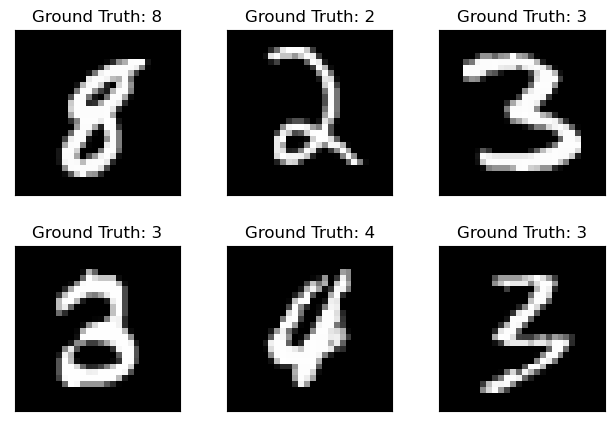

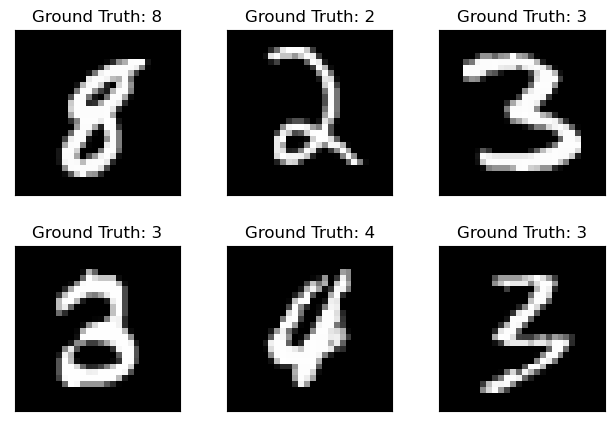

In [5]:
import matplotlib.pyplot as plt

examples = enumerate(test_loader)
batch_idx, (example_data, example_targets) = next(examples)
print(f'Shape: {example_data.shape}')

fig = plt.figure()
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    plt.title("Ground Truth: {}".format(example_targets[i]))
    plt.xticks([])
    plt.yticks([])
fig

A continuación se va a definir la arquitectura del modelo. En general, suele ser recomendable utilizar programación orientada a objetos y definir una clase para el modelo, pues el código así resulta más ordenado y, por tanto, menos proclive a experimentar errores de programación. Además es más reutilizable y fácil de utilizar cuando ya se tiene cierta experiencia en este tipo de programación.

In [6]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 10, kernel_size=5)
        self.conv2 = nn.Conv2d(10, 20, kernel_size=5)
        self.conv2_drop = nn.Dropout2d()
        self.fc1 = nn.Linear(320, 50)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x):
        x = F.relu(F.max_pool2d(self.conv1(x), 2))
        x = F.relu(F.max_pool2d(self.conv2_drop(self.conv2(x)), 2))
        x = x.view(-1, 320)
        x = F.relu(self.fc1(x))
        x = F.dropout(x, training=self.training)
        x = self.fc2(x)
        return F.log_softmax(x)

Hemos visto que en el constructor se definen las capas del modelo, en este caso convolucionales (se estudiarán más adelante), funciones de activación ReLU y drop-outs, con salida en softmax. La función softmax viene a ser una generalización multinomial de una sigmoidea similar a la que se utiliza en la regresión logística, de modo que la suma de las salidas, teniendo todas y cada una de ellas valores positivos, es uno (como en la distribución multinomial).

In [7]:
network = Net()
optimizer = optim.SGD(network.parameters(), lr=learning_rate, momentum=momentum)

A continuación hemos instanciado esta clase en el objeto "net" y hemos creado un optimizador, basado en SGD. A continuación se van a utilizar ambos objetos para entrenar la red neuronal por los bacthes del data_loader.

In [8]:
# Train
#########
train_losses = []
train_counter = []

def train(epoch):
    network.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = network(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))
            train_losses.append(loss.item())
            train_counter.append((batch_idx*64) + ((epoch-1)*len(train_loader.dataset)))
            torch.save(network.state_dict(), 'temp/model.pth')
            torch.save(optimizer.state_dict(), 'temp/optimizer.pth')

# Test
#######
test_losses = []
test_counter = [i*len(train_loader.dataset) for i in range(n_epochs + 1)]

def test():
    network.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            output = network(data)
            test_loss += F.nll_loss(output, target, size_average=False).item()
            pred = output.data.max(1, keepdim=True)[1]
            correct += pred.eq(target.data.view_as(pred)).sum()
    test_loss /= len(test_loader.dataset)
    test_losses.append(test_loss)
    print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
            test_loss, correct, len(test_loader.dataset),
            100. * correct / len(test_loader.dataset)))
    


Una vez definidos los procedimientos de test y train, pasemos a entrenar y testar el modelo:

In [9]:
test()
for epoch in range(1, n_epochs + 1):
    train(epoch)
    test()

C:\Users\Anna\AppData\Local\Temp\ipykernel_16728\161431047.py:17: UserWarning: Implicit dimension choice for log_softmax has been deprecated. Change the call to include dim=X as an argument.
  return F.log_softmax(x)
C:\ProgramData\Anaconda3\lib\site-packages\torch\nn\_reduction.py:42: UserWarning: size_average and reduce args will be deprecated, please use reduction='sum' instead.
  warnings.warn(warning.format(ret))



Test set: Avg. loss: 2.3210, Accuracy: 1038/10000 (10%)

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.263315
Train Epoch: 1 [640/60000 (1%)]	Loss: 2.301886
Train Epoch: 1 [1280/60000 (2%)]	Loss: 2.336762
Train Epoch: 1 [1920/60000 (3%)]	Loss: 2.319590
Train Epoch: 1 [2560/60000 (4%)]	Loss: 2.284770
Train Epoch: 1 [3200/60000 (5%)]	Loss: 2.240950
Train Epoch: 1 [3840/60000 (6%)]	Loss: 2.206288
Train Epoch: 1 [4480/60000 (7%)]	Loss: 2.200512
Train Epoch: 1 [5120/60000 (9%)]	Loss: 2.220252
Train Epoch: 1 [5760/60000 (10%)]	Loss: 2.106470
Train Epoch: 1 [6400/60000 (11%)]	Loss: 1.939630
Train Epoch: 1 [7040/60000 (12%)]	Loss: 1.941573
Train Epoch: 1 [7680/60000 (13%)]	Loss: 1.785182
Train Epoch: 1 [8320/60000 (14%)]	Loss: 1.831889
Train Epoch: 1 [8960/60000 (15%)]	Loss: 1.722084
Train Epoch: 1 [9600/60000 (16%)]	Loss: 1.572581
Train Epoch: 1 [10240/60000 (17%)]	Loss: 1.432150
Train Epoch: 1 [10880/60000 (18%)]	Loss: 1.434864
Train Epoch: 1 [11520/60000 (19%)]	Loss: 1.458995
Train Epoch: 1 [12160

Train Epoch: 2 [44160/60000 (74%)]	Loss: 0.310998
Train Epoch: 2 [44800/60000 (75%)]	Loss: 0.438963
Train Epoch: 2 [45440/60000 (76%)]	Loss: 0.478256
Train Epoch: 2 [46080/60000 (77%)]	Loss: 0.276223
Train Epoch: 2 [46720/60000 (78%)]	Loss: 0.245310
Train Epoch: 2 [47360/60000 (79%)]	Loss: 0.319571
Train Epoch: 2 [48000/60000 (80%)]	Loss: 0.288134
Train Epoch: 2 [48640/60000 (81%)]	Loss: 0.283594
Train Epoch: 2 [49280/60000 (82%)]	Loss: 0.504083
Train Epoch: 2 [49920/60000 (83%)]	Loss: 0.491597
Train Epoch: 2 [50560/60000 (84%)]	Loss: 0.289435
Train Epoch: 2 [51200/60000 (85%)]	Loss: 0.314037
Train Epoch: 2 [51840/60000 (86%)]	Loss: 0.213700
Train Epoch: 2 [52480/60000 (87%)]	Loss: 0.563542
Train Epoch: 2 [53120/60000 (88%)]	Loss: 0.443703
Train Epoch: 2 [53760/60000 (90%)]	Loss: 0.407609
Train Epoch: 2 [54400/60000 (91%)]	Loss: 0.336856
Train Epoch: 2 [55040/60000 (92%)]	Loss: 0.281177
Train Epoch: 2 [55680/60000 (93%)]	Loss: 0.348337
Train Epoch: 2 [56320/60000 (94%)]	Loss: 0.380084


Como vemos, el error va bajando tanto en el conjunto de train como en el de test, aunque con algunas oscilaciones. Podemos ver esta dinámica de forma gráfica a continuación:

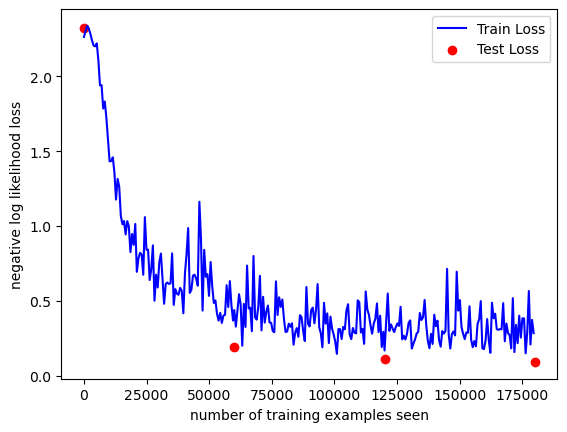

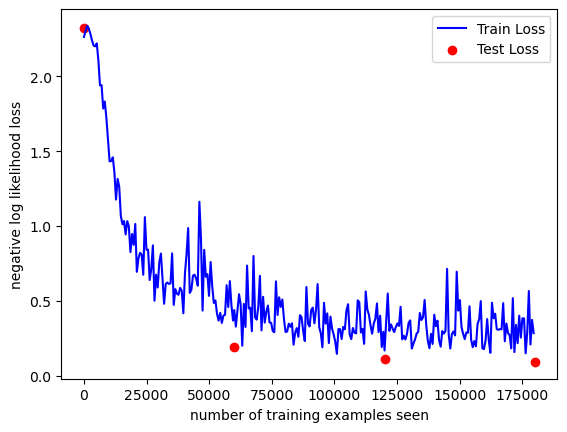

In [10]:
fig = plt.figure()
plt.plot(train_counter, train_losses, color='blue')
plt.scatter(test_counter, test_losses, color='red')
plt.legend(['Train Loss', 'Test Loss'], loc='upper right')
plt.xlabel('number of training examples seen')
plt.ylabel('negative log likelihood loss')
fig

### 3.1.2.- TensorFlow / Keras

TensorFlow es una librería desarrollada por Google Brain y que inicialmente fue utilizada en su versión original (DistBelief) por los propios equipos de Google, pero que fue abierto su código y compartido a la comunidad en noviembre de 2015 para su uso con Python y C++. La versión 2.0 fue lanzada en 2019, haciéndola más manejable y fácil de utilizar.

El nombre de "TensorFlow" proviene de la idea de que durante el entrenamiento de la red se produce un "flujo de tensores", siendo un tensor la generalización de la idea de matriz a más de dos dimensiones, es decir, una matriz de vectores, de matrices o, de forma recurrente, de tensores.

TensorFlow puede funcionar tanto en GPU como en CPU, aunque es recomendable entrenar los modelos en GPUs bajo el software CUDA de Nvidia. Google/Alphabet desarrolló su propio sistema de procesamiento en paralelo a semejanza de las GPU, TPU (Tensor Processing Unit), pero adaptado al uso en deep learning, hacia 2015 y lo empezó a ofrecer al público en 2018.

La librería Keras, aunque inicialmente se instalaba por separado porque operaba a nivel macro con TensorFlow, hace unos años paso a estar incluida también dentro de TensorFlow ("tensorflow.keras"), pues en la mayoría de los casos podemos desarrollar nuestros modelos en Keras ya que no necesitamos bajar al nivel de detalle que ofrece TensorFlow.

Otra gran ventaja de TensorFlow son sus múltiples extensiones de código abierto, desde el interfaz de monitorización para el entrenamiento TensorBoard hasta diferentes módulos que vienen a ser variantes ofrecidas por Alphabet:
- TensorFlow lite (TF Lite): para implementar redes neuronales profundas en dispositivos embebidos (Raspberry Pi, pequeñas CPUs en cámaras, etc.) 
- TensorFlow javascript (tensorflow.js): para implementar modelos en el navegador web, generalmente en la parte cliente, lo que permite reducir peso de cálculo al servidor.
- TensorFlow extended (TFX): para la productivización eficiente de los modelos resultantes.
- TensorFlow probabilistic (TFP): ofreciendo nuevos modelos de deep learning en su versión probabilísitica. 
- TensorFlow federated (TFF): orientada al aprendizaje descentralizado garantizando al mismo tiempo la privacidad del dato.

In [11]:
#!pip install tensorflow

In [12]:
import tensorflow as tf
import tensorflow_datasets as tfds

Como veremos, la librería tensorflow será la encargada de realizar la derivación automática, mientras que tensorflow_datasets nos propocionará los conjuntos de datos de entrada.

In [13]:
(ds_train, ds_test), ds_info = tfds.load(
    'mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    with_info=True,
)

La librería tensorflow_datasets nos proporciona varias formas de obtener los datos, para lo cual debemos recurrir a la documentación y utilizar los parámetros por defecto o modificar aquello que no se ajuste a nuestras necesidades.
Los datos de MNIST se pueden obtener de otras múltiples fuentes, pero descargarlos a través de tensorflow_datasets nos simplifica su posterior uso posterior con TensorFlow. En general necesitamos disponer de conexión a internet para que se produzca la descarga, pues tensorflow_datasets es únicamente un interfaz para descargar datos del cloud.

In [14]:
def normalize_img(image, label):
    return tf.cast(image, tf.float32) / 255., label

ds_train = ds_train.map(normalize_img, num_parallel_calls=tf.data.AUTOTUNE)
ds_train = ds_train.cache()
ds_train = ds_train.shuffle(ds_info.splits['train'].num_examples)
ds_train = ds_train.batch(128)

Aquí hemos realizado una transformación del formato de datos a float y preparado las muestras por mini-batches en el conjunto de train.

In [15]:
ds_test = ds_test.map(normalize_img, num_parallel_calls=tf.data.AUTOTUNE)
ds_test = ds_test.batch(128)
ds_test = ds_test.cache()
ds_test = ds_test.prefetch(tf.data.AUTOTUNE)

Hacemos lo mismo en el conjunto de test con el fin de monitorizar que no se produce sobreajuste.
A continuación vamos a definir el modelo, en primer lugar, para después compilarlo y, por último, entrenarlo:
- Definición: disponemos de entradas de 28x28 pixels, tras lo cual añadimos una capa fully-connected de 128 neuronas y función de activación ReLU, disponiendo de la capa final de 10 neuronas (los diez dígitos a predecir)
- Compilación: asignamos en este caso el optimizador Adam con un ratio de aprendizaje de 0.001 y función de pérdida una variedad de cross-entropy (para variables categóricas y etiquetas directas 0-9 sin one-hot-encoding), añadiendo métricas par hacer seguimiento más detallado de la evolución del ajuste.
- Entrenamiento: nuestra CPU o GPU empieza a entrenar el modelo, buscando los valores óptimos de los parámetros para predecir con la mejor precisión como sea posible los 10 dígitos.

In [16]:
# Definimos el modelo
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dense(10)
])

# Lo compilamos asignando la función de pérdida, el optimizador y las estadísticas.
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy()],
)

# Entrenamos el modelo unas cuantas iteraciones
model.fit(
    ds_train,
    epochs=6,
    validation_data=ds_test,
)

Epoch 1/6
469/469 [==============================] - 4s 4ms/step - loss: 0.3645 - sparse_categorical_accuracy: 0.9007 - val_loss: 0.1974 - val_sparse_categorical_accuracy: 0.9420
Epoch 2/6
469/469 [==============================] - 1s 3ms/step - loss: 0.1652 - sparse_categorical_accuracy: 0.9524 - val_loss: 0.1357 - val_sparse_categorical_accuracy: 0.9607
Epoch 3/6
469/469 [==============================] - 1s 3ms/step - loss: 0.1187 - sparse_categorical_accuracy: 0.9666 - val_loss: 0.1096 - val_sparse_categorical_accuracy: 0.9674
Epoch 4/6
469/469 [==============================] - 1s 3ms/step - loss: 0.0911 - sparse_categorical_accuracy: 0.9739 - val_loss: 0.1010 - val_sparse_categorical_accuracy: 0.9706
Epoch 5/6
469/469 [==============================] - 1s 3ms/step - loss: 0.0747 - sparse_categorical_accuracy: 0.9784 - val_loss: 0.0884 - val_sparse_categorical_accuracy: 0.9740
Epoch 6/6
469/469 [==============================] - 1s 3ms/step - loss: 0.0616 - sparse_categorical_accu

Vemos que el accuracy en validation ha ido incrementándose mientras que las pérdidas han ido disminuyendo. Obsérvese que, aunque el error en validación es ligeramente mayor, ambos han seguido un ritmo decreciente bastante consistente, por lo que podemos considerar que no ha existido sobre-ajuste (al menos para estas 6 primeras iteraciones).

### 3.1.3.- Librerías de alto nivel

#### PyTorch Lightning
PyTorch Lightning es el marco de aprendizaje profundo para investigadores profesionales de IA e ingenieros de aprendizaje automático que necesitan la máxima flexibilidad sin sacrificar el rendimiento a escala.
Como veremos, la librería Pytorch Lightning puede incorporar lenguaje a más bajo nivel existente en PyTorch, de modo que nos servirá principalmente para acelerar tiempo reutilizando código ya empaquetado (los "bolts", reutilización modelos y extructuras ya desarrollados), como vimos sucedía con Keras y otros frameworks como Theano, Lasagne o Tensorflow.

In [17]:
#!pip install pytorch-lightning

In [18]:
import os
import pandas as pd
import seaborn as sn
import torch
from IPython.core.display import display
from pytorch_lightning import LightningModule, Trainer
from pytorch_lightning.callbacks.progress import TQDMProgressBar
from pytorch_lightning.loggers import CSVLogger
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, random_split
from torchmetrics import Accuracy
from torchvision import transforms
from torchvision.datasets import MNIST

PATH_DATASETS = os.environ.get("PATH_DATASETS", ".")
BATCH_SIZE = 256 if torch.cuda.is_available() else 64

C:\Users\Anna\AppData\Local\Temp\ipykernel_16728\922065957.py:5: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display


In [19]:
class MNISTModel(LightningModule):
    def __init__(self):
        super().__init__()
        self.l1 = torch.nn.Linear(28 * 28, 10)

    def forward(self, x):
        return torch.relu(self.l1(x.view(x.size(0), -1)))

    def training_step(self, batch, batch_nb):
        x, y = batch
        loss = F.cross_entropy(self(x), y)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=0.02)

In [20]:
# Init our model
mnist_model = MNISTModel()

# Init DataLoader from MNIST Dataset
train_ds = MNIST(PATH_DATASETS, train=True, download=True, transform=transforms.ToTensor())
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE)

# Initialize a trainer
trainer = Trainer(
    accelerator="auto",
    devices=1 if torch.cuda.is_available() else None,  # limiting got iPython runs
    max_epochs=3,
    callbacks=[TQDMProgressBar(refresh_rate=20)],
)

# Train the model
trainer.fit(mnist_model, train_loader)

  0%|          | 0/9912422 [00:00<?, ?it/s]

Extracting .\MNIST\raw\train-images-idx3-ubyte.gz to .\MNIST\raw



  0%|          | 0/28881 [00:00<?, ?it/s]

Extracting .\MNIST\raw\train-labels-idx1-ubyte.gz to .\MNIST\raw



  0%|          | 0/1648877 [00:00<?, ?it/s]

...

  0%|          | 0/4542 [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True, used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs


Extracting .\MNIST\raw\t10k-labels-idx1-ubyte.gz to .\MNIST\raw



INFO:pytorch_lightning.accelerators.gpu:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name | Type   | Params
--------------------------------
0 | l1   | Linear | 7.9 K 
--------------------------------
7.9 K     Trainable params
0         Non-trainable params
7.9 K     Total params
0.031     Total estimated model params size (MB)
C:\Users\Anna\AppData\Roaming\Python\Python39\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:240: PossibleUserWarning: The dataloader, train_dataloader, does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` (try 12 which is the number of cpus on this machine) in the `DataLoader` init to improve performance.
  rank_zero_warn(


Training: 0it [00:00, ?it/s]

#### Fast.ai

Fast.ai es una librería de aprendizaje profundo de alto nivel desarrollada por Jeremy Howard y Rachel Thomas, dos de los más reputados Data Scientist del mundo. El objetivo de esta librería es proporcionar componentes de alto nivel que pueden proporcionar rápida y fácilmente resultados de última generación en dominios de aprendizaje profundo estándar, proporcionando también componentes de bajo nivel que se pueden mezclar y combinar para construir nuevos enfoques. Howard y Thomas ofrecen también de forma gratuita una serie de cursos online gratuitos para aprender deep learning a fondo utilizando tanto fast.ai como Tensorflow o PyTorch directamente en la dirección https://course.fast.ai

In [23]:
#!pip install fastai

  Using cached typer-0.7.0-py3-none-any.whl (38 kB)


In [24]:
from fastai.vision.all import *
from fastai.callback.hook import summary
from fastai.callback.schedule import fit_one_cycle, lr_find 
from fastai.callback.progress import ProgressCallback
from fastai.data.core import Datasets, DataLoaders, show_at
from fastai.data.external import untar_data, URLs
from fastai.data.transforms import Categorize, GrandparentSplitter, parent_label, ToTensor, IntToFloatTensor, Normalize
from fastai.layers import Flatten
from fastai.learner import Learner
from fastai.metrics import accuracy, CrossEntropyLossFlat
from fastai.vision.augment import CropPad, RandomCrop, PadMode
from fastai.vision.core import PILImageBW
from fastai.vision.utils import get_image_files

from torch import nn

Como vemos, se están llamando funciones de callback (para invocar funcionalidades de bajo nivel), data (para importar y tratar datos), vision (para problemas de computer vision como el ejemplo de MNIST) y otras indispensables y bien reconocibles como layers, learner o metrics.
Se puede observar que era posible escribir únicamente "from fastai import * " para no tener tantas líneas de código, pero téngase en cuenta que siempre es mejor cargar únicamente lo que vamos a utilizar (además de que así queda más limpio y abreviado el código posterior).

In [25]:
path = untar_data(URLs.MNIST)
items = get_image_files(path)
splits = GrandparentSplitter(train_name='training', valid_name='testing')
splits = splits(items)
dsrc = Datasets(items, tfms=[[PILImageBW.create], [parent_label, Categorize]], splits=splits)
tfms = [ToTensor(), CropPad(size=34, pad_mode=PadMode.Zeros), RandomCrop(size=28)]
gpu_tfms = [IntToFloatTensor(), Normalize()]

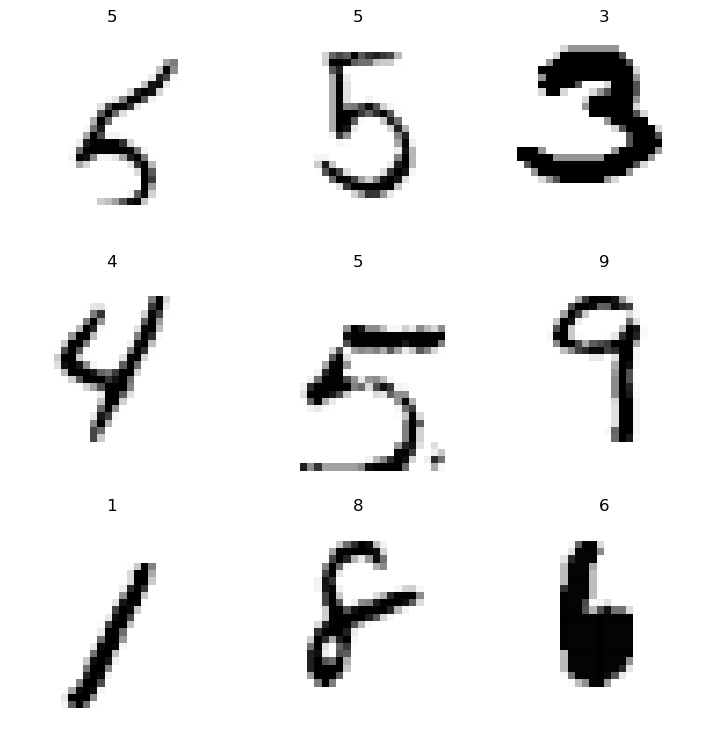

In [26]:
dls = dsrc.dataloaders(bs=128, after_item=tfms, after_batch=gpu_tfms)
dls.show_batch()
xb, yb = dls.one_batch()

In [27]:
model = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, stride=2, padding=1),
    nn.BatchNorm2d(8),
    nn.ReLU(inplace=False),
    nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(inplace=False),
    nn.Conv2d(16,32, kernel_size=3, stride=2, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(inplace=False),
    nn.Conv2d(32, 16, kernel_size=3, stride=2, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(inplace=False),
    nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1),
    nn.BatchNorm2d(10),
    Flatten()
)

learn = Learner(dls, model, loss_func=CrossEntropyLossFlat(), metrics=accuracy)

In [28]:
learn.summary()

Sequential (Input shape: 128 x 1 x 28 x 28)
Layer (type)         Output Shape         Param #    Trainable 
                     128 x 8 x 14 x 14   
Conv2d                                    80         True      
BatchNorm2d                               16         True      
ReLU                                                           
____________________________________________________________________________
                     128 x 16 x 7 x 7    
Conv2d                                    1168       True      
BatchNorm2d                               32         True      
ReLU                                                           
____________________________________________________________________________
                     128 x 32 x 4 x 4    
Conv2d                                    4640       True      
BatchNorm2d                               64         True      
ReLU                                                           
____________________________________

SuggestedLRs(valley=0.007585775572806597)

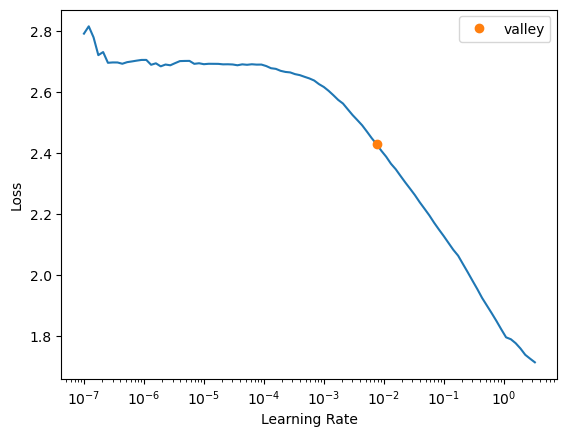

In [29]:
learn.lr_find()

### 3.1.4.- Otras librerías de aprendizaje profundo
      

Desde el ámbito científico existen o han existido otros frameworks alternativos a TensorFlow o PyTorch, como Caffe2 (especializado en redes convolucionales), Torch (antecedente de PyTorch, escrito en el lenguaje Lua), DeepLearning4J (desarrollado para Java) o CNTK (desarrollado por Microsoft), que surgieron a la vez que los anteriores. Posteriormente también se han adaptado librerías para Matlab y R, pero es importante tener en cuenta que dominar el lenguaje python nos permite disponer de las últimas novedades lo antes posible y con una óptima integración con todo tipo de sistemas.

## 3.2.- Herramientas auxiliares

### 3.2.1.- Entornos cloud

Los principales proveedores de cloud (Amazon Web Services, Google Cloud Platform y Microsoft Azure) disponen de gran variedad de máquinas virtuales y otros servicios completamente integrables tanto con PyTorch como con TensorFlow.

Además, disponen de framworks de desarrollo de modelos en los que se pueden entrenar y desplegar modelos propios de la compañía a través de diferentes servicios cognitivos que aceleran el desarrollo end-to-end del trabajo de modelización, como AWS SageMaker, Google Vertex AI o Azure ML.

<img src="images/gcp_aws_az.png" width="700" height="300" />

### 3.2.2.- Herramientas de visualización
      

A la hora de entrenar modelos de deep learning, el investigador/desarrollador necesita entender qué está ocurriendo durante el proceso de aprendizaje, pues ello le ayudará a entender cómo ajustar ciertos hiper-parámetros y a depurar el código con una mayor probabilidad de éxito.

Entre estas herramientas destaca por su popularidad y utilización **TensorBoard**, desarrollada por el equipo de Google/TensorFlow, que permite analizar desde la arquitectura de la red neuronal como los ratios de aprendizaje en los conjuntos entrenamiento y su evaluación en test. También dispone de funcionalidades gráficas para analizar la similitud entre imágenes y diversos gráficos altamente customizables según las necesidades de cada desarrollador.

Existen otras herramientas alternativas que no sólo sirven para el proceso de entrenamiento y validación, sino que también ayudan a organizar las distintas versiones de modelos, comparar entre ellos, facilitar las tareas de despliegue y reutilizarlos fácilmente. Entre estas herramiemntas destacan:

* **MLFlow**: plataforma de código abierto para administrar el ciclo de vida de ML, incluida la experimentación, la reproducibilidad, la implementación y un registro de modelo central. MLflow actualmente ofrece cuatro componentes: MLflow Tracking, MLflow Projects, MLflow Models y MLflow Registry.
* **Comet**: se integra con su infraestructura y herramientas existentes para que pueda administrar, visualizar y optimizar modelos, desde ejecuciones de capacitación hasta monitoreo de producción.
* **Weight & Biases**: plataforma de aprendizaje automático para que los desarrolladores construyan mejores modelos más rápido, crear versiones e iterar conjuntos de datos, evaluar el rendimiento del modelo, reproducir modelos, visualizar resultados y detectar regresiones, y compartir hallazgos con colegas.
* **Captum**: proporciona algoritmos de última generación, incluidos los gradientes integrados, para proporcionar a los investigadores y desarrolladores una manera fácil de comprender qué características contribuyen a la salida de un modelo.

Existen también otras muchas herramientas similares, entre las que cabría destacar Neptune, Sacred, Guild AI, etc.

<div class="col" style="float:left">
    <img src="images/tensorboard_2.png" width="450" height="300" />
</div>
<div class="col" style="float:right">
    <img src="images/tensorboard_1.png" width="450" height="300" />
</div>

## 3.3.- Herramientas para reutilizar código abierto

Hoy en día los desarrolladores no solemos recordar demasiado bien la sintaxis de todas estas librerías, pues, tal y como se trabaja, es difícil de memorizar y se trata de módulos que están en constante cambio. Contamos, por suerte, con múltiples recursos para reutilizar código y de trabajo colaborativo para modificar o ampliar y esto hace que recursos como StackOverflow o GitHub se conviertan en el mejor amigo del programador.

En este curso, que consta de muy pocas horas y con un temario muy amplio, no podemos pretender que los alumnos lleguen a memorizar el código que se utiliza, pues muy pocos lo hacen y no tendría sentido. En su lugar, lo que es importante es aprender a buscar e interactuar con estos recursos de modo que el alumno adquiera cierta autonomía para poder trabajar de modo independiente al final de la asignatura. En este apartado, por tanto, pasaremos a describir cuál es son estos recursos y a través de los laboratorios aprenderemos a usarlos.

### 3.3.1.- Instalación / Colab

Aunque hace unos años nos suponía un importante quebradero de cabeza, por suerte hoy en día las librerías TensorFlow y PyTorch resultan muy fáciles de instalar tanto para Windows, Mac o Linux, existan o no GPUs. Para llevar a cabo esta instalación, debemos seguir la documentación y en pocos minutos tendremos las librerías instaladas.

Es una buena práctica crear "**entornos**", bien sea a través de conda como de virtualenv, pues esto nos eviytará conflictos entre librerías y que nuestros programas antiguos dejen de funcionar o que su estructura de librerías impidan el funcionamiento de los nuevos.

Si todavía queremos no sea necesario ni instalar las librerías, disponiendo además puntualmente de GPUs/TPUs a nuestra disposición, podemos abrir una cuenta gratuita en **Google Colaboratory (Colab)**. Colab permite a cualquier usuario escribir y ejecutar código arbitrario de Python en el navegador, siendo especialmente adecuado para pruebas de prototipado y educación. Colab, además, se integra fácilmente con Google Drive, también gratuito, lo que nos permite disponer de Jupyter Notebooks con fácil acceso a dichos datos. El inconveniente es que, en función a la carga de trabajo, podrán cortarnos o ralentizarnos nuestro proceso sin previo aviso, de modo que en general es utilizado únicamente para pruebas y aprendizaje.

Adicionalmente existen otros entornos similares de pago o gratuitos, como Paperspace Gradient (de los autores de fast.ai), FloydHub (con tiempo gratuito de uso) o los provistos por AWS (Sagemaker), Google (Vertex) o Azure (ML), que suelen disponer también de bastantes horas de uso gratuito.

### 3.3.2.- Servicios de apoyo a la programación

Muchos desarrolladores coincidimos en que si StackOverflow se cayera, no podríamos apenas programar y deberíamos tomarnos el día libre esperando a que se reestaurara el servicio. En **StackOverflow** están respondidoas casi todas las preguntas que pudiéramos tener y, en caso de no estarlo, se puede formular (con los modelos precisos) nuestra nueva pregunta y es probable que otro programador acuda a nuestro auxilio en poco tiempo. Desde luego, otra alternativa es acudir directamente a **Google** y "copy-paste-ar" nuestro error, pero nos exponemos a encontrar respuestas no demasiado adecuadas o que nos redirijan a servidores con mucho spam, pero vale la pena intentarlo.

Otra herramienta indispensable hoy en día para los Data Scientists es **GitHub**, un servicio de repositorio cloud de código y control de versiones mediante Git. GitHub permite el desarrollo colaborat hacer commitivo de código, pues dispone de control de acceso, seguimiento de errores, solicitudes de funciones de software, gestión de tareas, integración continua y wikis para cada proyecto, etc. Se trata de una compañía subsidiaria de Microsoft desde 2018, pero que se utiliza comúnmente para albergar proyectos de desarrollo de software de código abierto. A partir de junio de 2022, GitHub informó tener más de 83 millones de desarrolladores y más de 200 millones de repositorios, incluidos al menos 28 millones de repositorios públicos, siendo el host de código fuente más grande del mundo.
Para utilizar GitHub debemos abrirnos una cuenta gratuita (podemos disponer de repositorios privados y otras ventajas en la alternativa de pago) y empezar a subir código para conservarlo y evolucionarlo evitando todo tipo de disgustos por perder el trabajo de horas, días o semanas. Aunque dispone de muchas opciones, la operativa básica es muy sencilla:
* "git clone": para bajar cóigo de la nube
* "git add .": para incluir ficheros adicionales
* "git commit -m <>": para actualizar el código en el repositorio
* "git push": para subir a la nube nuestro código tras hacer commit
* "git pull": para traernos la última versión

En la actualidad están proliferando los programas de "**autopilot**", cada vez más potentes, y es previsoble que dichos servicios sigan desarrollándose rápidamente en vistas a la eficacia de sistemas inteligentes basados en redes neuronales como **ChatGPT**. Es decir, más que programar "from scratch", debemos adaptarnos al modo de programar de nuestro tiempo y dejarnos ayudar por estas tecnologías aprovechándolas al máximo, pues otros también lo harán y, si nosotros no lo hacemos, serán más rápidos y eficientes que nosotros.

### 3.3.3.- Plataformas de competición y aprendizaje

Hoy en día existen en internet multitud de cursos y vídeos para aprender Data Science. Cualquier que quiera aprender y no lo haga, no será porque notenga medios. No voy a poner aquí enlaces, pues se pueden acudir a ellos con una rápida búsqueda, pero tanto en **Youtube** se disponen de muy buenos cursos gratuitos, tanto en inglés como en español, o **MOOCs** como Udemy, Coursera o EDX, con cursos en algunos casos gratuitos o muy baratos, pagándose normalmente por el examen y certificado, no tanto por el curso en sí.

Dentro de las plataformas de aprendizaje y competición, la más conocida es **Kaggle**. Se trata de un lugar de encuentro de Data Scientists en donde se comparte código, datos y se llevan a cabo competiciones en las que demostrar nuestras habilidades. Kaggle dispone también de servidores en los que ejecutar nuestro código y es un escaparate excelente para la caza de talentos, de modo que destacar en estas competiciones, además de servirte de aprendizaje, te suele facilitar el acceso a ofertas de trabajo por todo el mundo en las tecnológicas más importantes.

Por último, decir que aquellos que quieran utilizar su tiempo para resolver problemas de Data Science aplicados a ayudar a ONGs, disponen de iniciativas como **DataKind**, en la que se desarrollan modelos aplicados a mejorar la vida de los más necesitados.

**Bibliografía y enlaces relacionados:**
- https://medium.com/@vineetjaiswal/introduction-comparison-of-mlops-platforms-aws-sagemaker-azure-machine-learning-gcp-vertex-ai-9c1153399c8e